1. Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install category_encoders

In [2]:

df = pd.read_excel('/content/2iRfEStgKkB5Ged2sqiSELxN4k8hrLKV.xlsx')


2. Preview the Dataset

In [3]:
df.head(5)

,Area_sqm,Neighborhood,Bedrooms,Bathrooms,Property_Age_Years,Price_EGP
0,120,الشيخ زايد,3,2,5,4200000
1,95,أكتوبر,2,1,8,2450000
2,160,التجمع الخامس,3,2,4,6100000
3,75,فيصل,2,1,15,1250000
4,210,المعادي,4,3,10,7800000


In [4]:
df.tail()

,Area_sqm,Neighborhood,Bedrooms,Bathrooms,Property_Age_Years,Price_EGP
25,130,أكتوبر,3,2,9,3400000
26,72,فيصل,2,1,13,1050000
27,150,مدينة نصر,3,2,7,4450000
28,220,الشيخ زايد,4,3,3,8900000
29,108,الشروق,3,1,5,3200000


3. Dataset Dimensions

In [5]:
df.shape

(30, 6)

4. Check for Duplicate Values

In [6]:
df.duplicated().sum()

np.int64(0)

5. Dataset Information

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Area_sqm            30 non-null     int64 
 1   Neighborhood        30 non-null     object
 2   Bedrooms            30 non-null     int64 
 3   Bathrooms           30 non-null     int64 
 4   Property_Age_Years  30 non-null     int64 
 5   Price_EGP           30 non-null     int64 
dtypes: int64(5), object(1)
memory usage: 1.5+ KB


6. Statistical Summary

In [8]:
df.describe()

,Area_sqm,Bedrooms,Bathrooms,Property_Age_Years,Price_EGP
count,30.000000,30.000000,30.000000,30.000000,3.000000e+01
mean,134.033333,2.966667,1.866667,8.133333,4.294333e+06
std,45.965867,0.718395,0.776079,4.485481,2.445467e+06
min,65.000000,2.000000,1.000000,2.000000,9.800000e+05
25%,98.500000,2.250000,1.000000,5.000000,2.525000e+06
50%,127.500000,3.000000,2.000000,7.000000,4.050000e+06
75%,160.000000,3.000000,2.000000,10.000000,6.050000e+06
max,230.000000,4.000000,3.000000,20.000000,9.200000e+06


In [9]:
for col in df.columns:
    print(col,':',df[col].nunique())

Area_sqm : 29
Neighborhood : 9
Bedrooms : 3
Bathrooms : 3
Property_Age_Years : 16
Price_EGP : 30


7. Check for Missing Values

In [10]:
df.isnull().sum()

,0
Area_sqm,0
Neighborhood,0
Bedrooms,0
Bathrooms,0
Property_Age_Years,0
Price_EGP,0


In [11]:
num_columns = df.select_dtypes(exclude="object").columns
print("Numerical Columns:", num_columns)


Numerical Columns: Index(['Area_sqm', 'Bedrooms', 'Bathrooms', 'Property_Age_Years', 'Price_EGP'], dtype='object')


8. Correlation Analysis

In [12]:
corr_matrix = df[num_columns].corr()

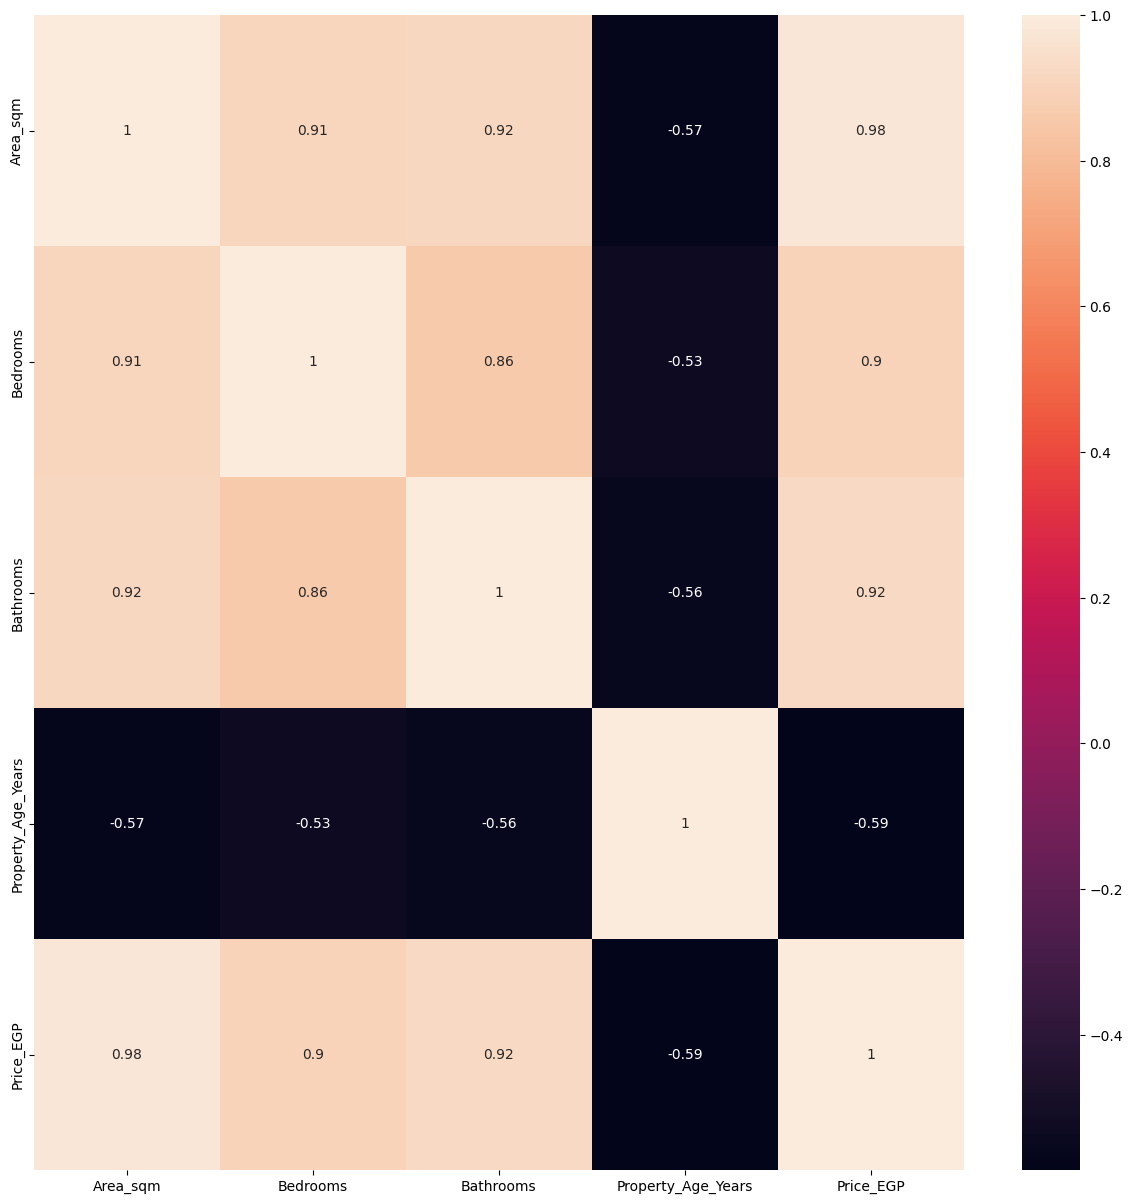

In [13]:
plt.figure(figsize=(15,15))
sns.heatmap(corr_matrix,annot=True)
plt.show()

9. Outlier Detection

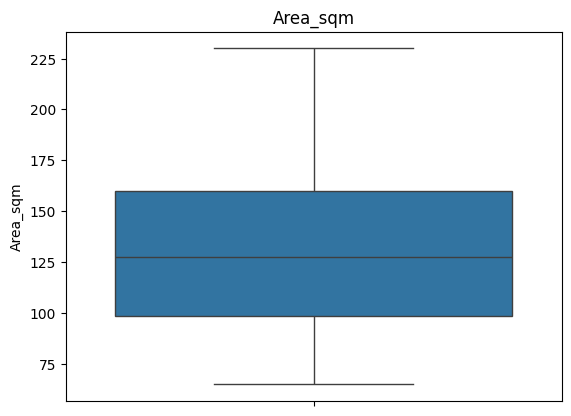

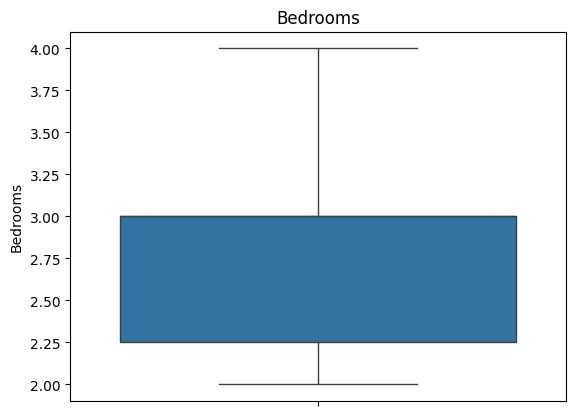

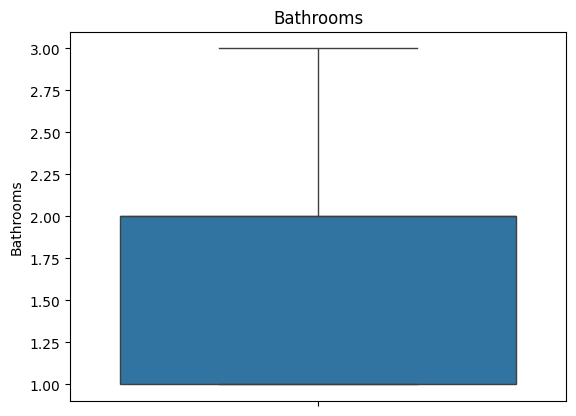

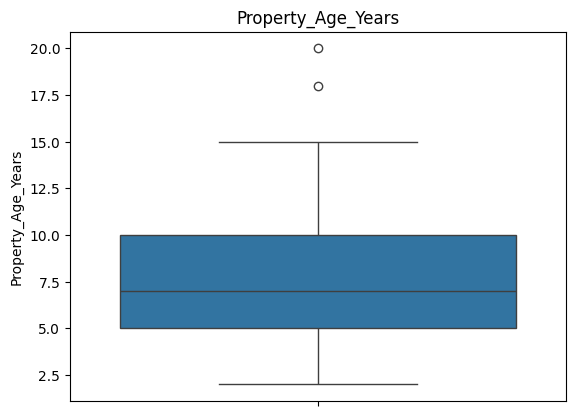

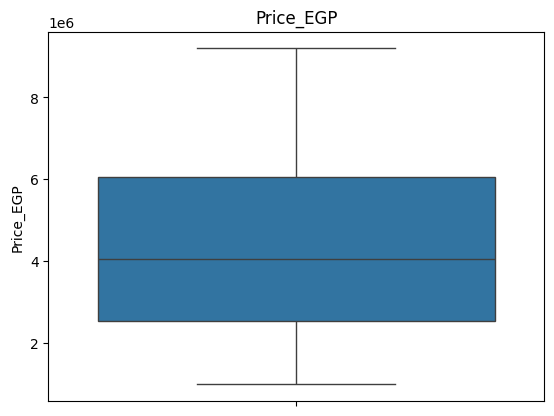

In [14]:
for i in num_columns:
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()

10. Price Distribution

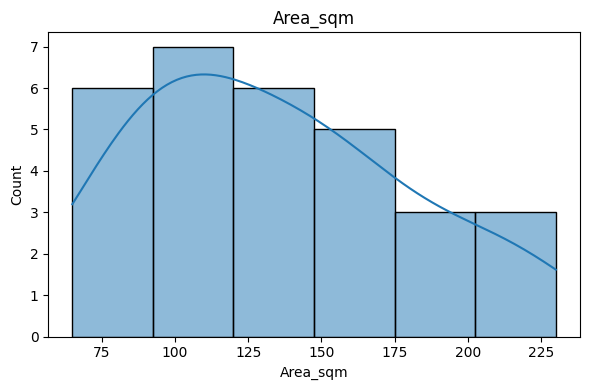

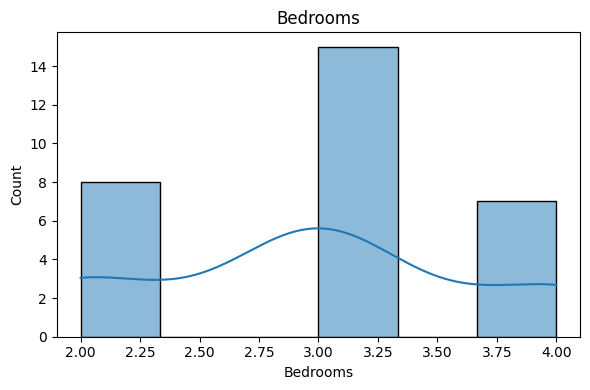

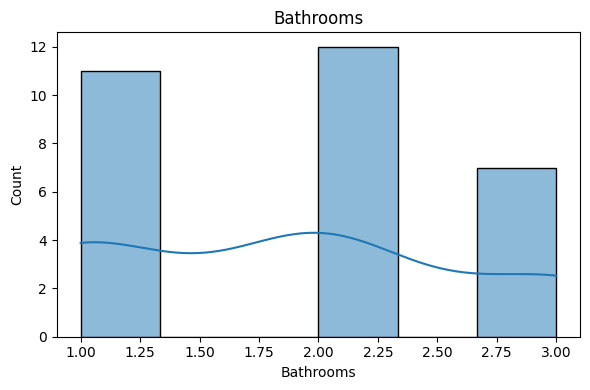

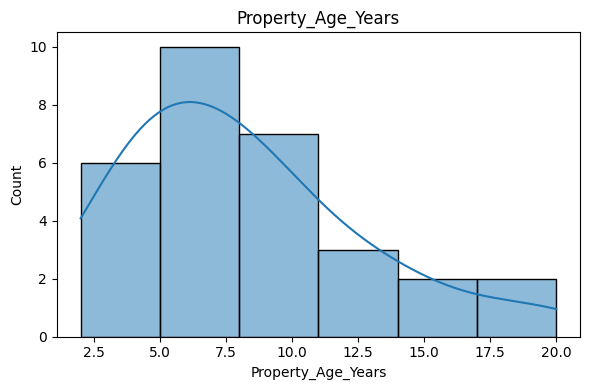

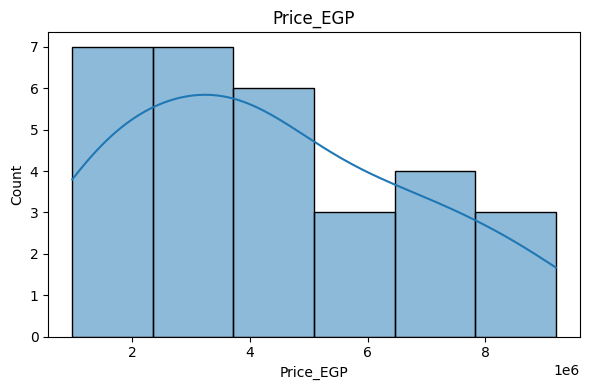

In [15]:
for col in num_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.tight_layout()
    plt.show()

11. Define Features and Target

In [16]:
X = df[['Area_sqm', 'Neighborhood', 'Bedrooms']]
y = df['Price_EGP']


12. Split Data into Training and Testing Sets

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 3)
Testing data: (6, 3)


13. Data Preprocessing and Model Pipeline

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from category_encoders import TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Features and target
X = df[['Area_sqm', 'Neighborhood', 'Bedrooms']]
y = df['Price_EGP']

# Define columns
categorical_features = ['Neighborhood']
numeric_features = ['Area_sqm', 'Bedrooms']

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('neighborhood', TargetEncoder(), categorical_features),
        ('numeric', StandardScaler(), numeric_features)
    ]
)

# Pipeline
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

14. Train the Model

In [19]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('neighborhood',
                                                  TargetEncoder(),
                                                  ['Neighborhood']),
                                                 ('numeric', StandardScaler(),
                                                  ['Area_sqm', 'Bedrooms'])])),
                ('regressor', LinearRegression())])

15. Make Predictions

In [20]:
y_pred = model.predict(X_test)

16. Model Evaluation

In [21]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("R²:", r2)

MAE: 274883.58193979255
R²: 0.9724982509807537


17. Predict the Price of a New Apartment

In [22]:
new_apartment = pd.DataFrame({
    'Area_sqm': [120],
    'Neighborhood': ['الشيخ زايد'],
    'Bedrooms': [3]
})

predicted_price = model.predict(new_apartment)[0]

print(f"Predicted Apartment Price: {predicted_price:,.2f} EGP")

Predicted Apartment Price: 4,293,437.68 EGP


## 18. Model Results and Conclusion

The HomeValue model was developed to predict apartment prices based on three main features:

* **Area (sqm)**
* **Neighborhood**
* **Number of Bedrooms**

A Linear Regression model was used with preprocessing techniques, including Target Encoding for the neighborhood and Standard Scaling for the numerical features.

### Evaluation Results

The model achieved the following results on the test data:

* **MAE:** 274,883.58 EGP
* **R² Score:** 0.9725 (**97.25%**)

### Interpretation

The **R² score of 97.25%** indicates that the model can explain a large portion of the variation in apartment prices within the test dataset.

The **MAE of approximately 274,884 EGP** means that, on average, the model's predicted apartment price differs from the actual price by around **275,000 EGP**.

### Conclusion

The results show that the model provides a good prediction of apartment prices using only the required inputs: area, neighborhood, and number of bedrooms.

However, the dataset contains only **30 records**, so the evaluation results should be considered experimental. A larger and more diverse dataset would be recommended to improve the model's reliability and its ability to generalize to real-world apartment prices.


## How to Run the Model

1. Open the `HomeValue.ipynb` file using **Google Colab** or **Jupyter Notebook**.

2. Upload the provided dataset file `apartment_data.xlsx` to the notebook environment.

3. Run the notebook cells **from top to bottom**.

4. The notebook will automatically:

   * Load and explore the dataset.
   * Check for missing and duplicate values.
   * Perform basic data visualization.
   * Prepare the input features and target variable.
   * Split the data into training and testing sets.
   * Preprocess the data and train the Linear Regression model.
   * Generate predictions.
   * Evaluate the model using **MAE** and **R²**.

5. To predict the price of a new apartment, enter the apartment's:

   * Area in square meters
   * Neighborhood
   * Number of bedrooms

6. The model will return the predicted apartment price in **EGP**.

### Required Libraries

The project uses:

* Pandas
* NumPy
* Scikit-learn
* Category Encoders
* Matplotlib
* Seaborn
